# How to Save? Churn Prediction and Retention Cost Optimization for a Bank

## 1. Project Introduction

Customer churn refers to customers leaving or discontinuing their relationship with a bank.

Customer churn is an important challenge in the banking industry because losing customers can affect business growth and profitability.

This project uses Machine Learning techniques to predict whether a bank customer is likely to leave the bank or continue using its services.

The main goal is to help banks identify potential churn customers and take suitable retention measures.

## 2. Problem Statement

Customer churn is a major challenge in the banking industry. When customers leave a bank, it can affect the bank's customer base and business growth.

The objective of this project is to develop a Machine Learning model that predicts whether a customer is likely to leave the bank.

The model will help identify potential churn customers so that banks can take appropriate retention actions.

## 3. Project Objectives

The main objectives of this project are:

- To analyse bank customer data and understand customer behaviour.
- To perform Exploratory Data Analysis (EDA).
- To clean and preprocess the dataset.
- To identify patterns related to customer churn.
- To build and evaluate different Machine Learning models.
- To select the best-performing model using suitable evaluation metrics.
- To explain model predictions using SHAP Explainability.
- To estimate the potential financial benefits of customer retention using Retention Cost Analysis.
- To suggest effective strategies to reduce customer churn and save costs.

## 4. Dataset Description

The dataset used in this project is the Bank Customer Churn dataset.  Dataset: BankChurners(Kaggle),10127 rows and 23 columns. 

It contains customer information related to demographics, banking relationships, transaction behaviour, and credit card usage.

The dataset contains:
- Total Records: 10,127
- Total Features: 23
- Target Variable: Attrition_Flag

The target variable indicates whether a customer has left the bank or continues to use its services.

- Attrited Customer: Customer who left the bank.
- Existing Customer: Customer who continues with the bank.

## 5. Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

### 6.Loading the data

In [2]:
df=pd.read_csv("dataset/BankChurners.csv")


In [3]:
df

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.999910
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.999940
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.999980
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.999870
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.999980
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,...,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462,0.000191,0.999810
10123,710638233,Attrited Customer,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,...,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511,0.995270,0.004729
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,...,5409.0,0,5409.0,0.819,10291,60,0.818,0.000,0.997880,0.002118
10125,717406983,Attrited Customer,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,...,5281.0,0,5281.0,0.535,8395,62,0.722,0.000,0.996710,0.003294


## EDA

### 7. Initial Data Inspection

In [4]:
df.shape #The dataset has 10127 rows and 23 columns.

(10127, 23)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

In [6]:
df.describe()

,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,0.159997,0.840003
std,3.690378e+07,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,0.365301,0.365301
min,7.080821e+08,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000008,0.000420
25%,7.130368e+08,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,0.000099,0.999660
50%,7.179264e+08,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,0.000181,0.999820
75%,7.731435e+08,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,0.000337,0.999900
max,8.283431e+08,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,0.999580,0.999990


#### Data types and summary
- All 23 columns have 10127 non-null values,so there are no true missing values."Unknown" is stored as text.

- 6 columns are text(object) and must be encoded before modelling:

- Attrition_Flag,Gender,Education_Level,Marital_Status,Income_Category,Card_Category.
- Customer age ranges from 26 to 73(mean about 46).No impossible ages.
- Credit_Limit mean(about 8632) is much higher than the median(4549), so a few customers have very high limits(right-skewed).
- CLIENTNUM is only an ID and will be dropped.


#### 8.Checking missing values

In [7]:
df.isnull().sum()


CLIENTNUM                                                                                                                             0
Attrition_Flag                                                                                                                        0
Customer_Age                                                                                                                          0
Gender                                                                                                                                0
Dependent_count                                                                                                                       0
Education_Level                                                                                                                       0
Marital_Status                                                                                                                        0
Income_Category                                 

##### isnull().sum() shows the count of missing values in all columns as 0.But some columns use the word "Unknown" for missing data,so the real missing values are hidden.Checked in the next step.

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Attrition_Flag"].value_counts()

Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64

### Target Variable: Attrition_Flag
- Existing Customers:8500
- Attrited Customers(Churned):1627
- The data is imbalanced:there are about 5 existing customers for every 1 customer who left.(8500 divided by 1627 is approximately 5.2)
- A model that predicts "Existing" for everyone would be correct for 8500 out of 10127 customers,but it would find none of the 1627 churners.So accuracy alone is not a good metric,and recall will be the main metric.
- Duplicate rows: 0

In [10]:
columns=["Gender","Education_Level","Marital_Status","Income_Category","Card_Category"]
for col in columns:
    print(df[col].value_counts())


Gender
F    5358
M    4769
Name: count, dtype: int64
Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64
Marital_Status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64
Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64
Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64


### Hidden Missing Values("Unknown") 
is null() showed no missing values,but "Unknown" is used as a placeholder in 3 text columns:
| Column | Unknown Count |
|---|---|
| Education_Level | 1519 |
| Marital_Status | 749 |
| Income_Category | 1112 |

- Gender and Card_Category have no "Unknown"
- These will be treated as missing values and handled in preprocesssing.
- Card_Category is very imbalanced: Blue has 9436 customers while platinum has only 20.

## Column description

| Column | Meaning | Type | Useful? |
|---|---|---|---|
| CLIENTNUM | Customer ID | int64 | No, it is only an ID |
| Attrition_Flag | Target: whether the customer left | object | Yes, this is the target |
| Customer_Age | Age of the customer | int64 | Yes, age may affect churn |
| Gender | Gender of the customer (F, M) | object | Yes, usage may differ by gender |
| Dependent_count | Number of people who depend on the customer financially | int64 | Yes, more dependents may change spending |
| Education_Level | Education level of the customer | object | Yes, but has 1519 Unknown values |
| Marital_Status | Married, Single or Divorced | object | Yes, but has 749 Unknown values |
| Income_Category | Annual income range of the customer | object | Yes, but has 1112 Unknown values |
| Card_Category | Type of card (Blue, Silver, Gold, Platinum) | object | Yes, very imbalanced (Blue 9436, Platinum 20) |
| Months_on_book | Months the customer has been with the bank | int64 | Yes, newer customers may have a weaker bond |
| Total_Relationship_Count | Number of bank products the customer uses | int64 | Yes, more products may mean less churn |
| Months_Inactive_12_mon | Months without card use in the last 12 months | int64 | Yes, inactive customers may be about to leave |
| Contacts_Count_12_mon | Times the customer contacted the bank in 12 months | int64 | Yes, many contacts may show dissatisfaction |
| Credit_Limit | Credit limit of the card | float64 | Yes, may relate to card usage. Has outliers |
| Total_Revolving_Bal | Unpaid balance carried on the card | int64 | Yes, shows how actively the card is used |
| Avg_Open_To_Buy | Credit still available to use | float64 | Yes, but it equals Credit_Limit minus Total_Revolving_Bal, so it repeats information |
| Total_Amt_Chng_Q4_Q1 | Change in spending amount, Q4 compared to Q1 | float64 | Yes, falling spending may signal churn |
| Total_Trans_Amt | Total amount spent in 12 months | int64 | Yes, low spending may signal churn. Has outliers |
| Total_Trans_Ct | Number of transactions in 12 months | int64 | Yes, few transactions may signal churn |
| Total_Ct_Chng_Q4_Q1 | Change in number of transactions, Q4 vs Q1 | float64 | Yes, falling transaction count may signal churn |
| Avg_Utilization_Ratio | Share of the credit limit that is used | float64 | Yes, low use may signal churn |
| Naive_Bayes_..._1 | Output of another model | float64 | No, will be dropped |
| Naive_Bayes_..._2 | Output of another model | float64 | No, will be dropped |

## EDA Charts
Charts to understand which customers leave the bank

#### Chart 1: Number of customers who stayed vs left

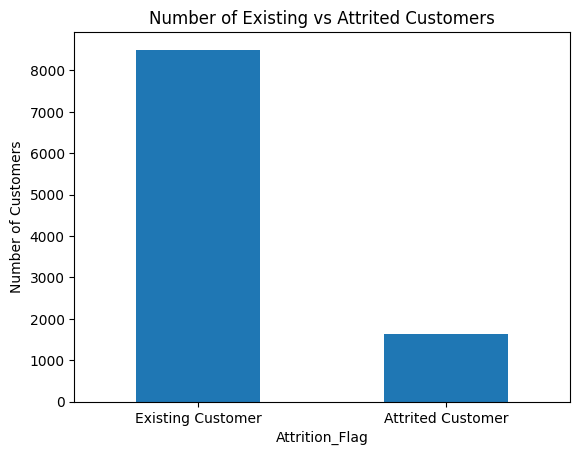

In [11]:
df["Attrition_Flag"].value_counts().plot(kind="bar")
plt.title("Number of Existing vs Attrited Customers")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

### Chart 1: Insights
- The "Existing Customer" bar is much taller than the
  "Attrited Customer" bar. There are about 8500 existing customers and
  about 1600 attrited customers.
- The data is imbalanced. Only a small share of
  customers left the bank.
- Accuracy alone can be misleading here. A model that
  predicts "Existing Customer" for everyone would still get a high
  accuracy, but it would not find a single customer who is going to
  leave. So recall will be used as the main evaluation metric.

### Chart 2: Customer Age and Churn
Are the customers who left older or younger than the customers who stayed?

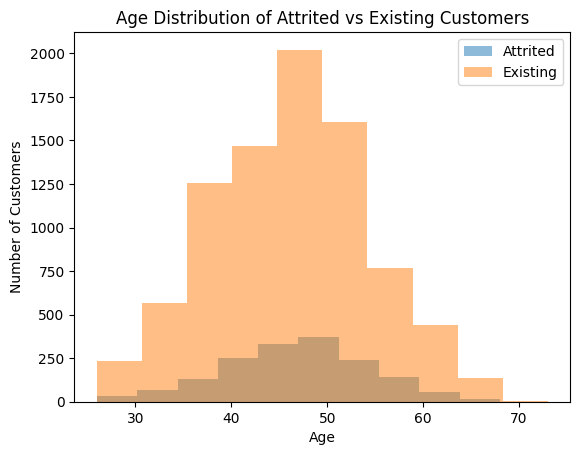

In [12]:
left=df[df["Attrition_Flag"]=="Attrited Customer"]
left.shape
stayed=df[df["Attrition_Flag"]=="Existing Customer"]
stayed.shape
plt.hist(left["Customer_Age"],label="Attrited",alpha=0.5)
plt.hist(stayed["Customer_Age"],label="Existing",alpha=0.5)
plt.legend()
plt.title("Age Distribution of Attrited vs Existing Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

In [13]:
left["Customer_Age"].mean()

np.float64(46.659496004917024)

In [14]:
stayed["Customer_Age"].mean()

np.float64(46.26211764705882)

### Chart 2: Insights
- Both attrited and existing customers have a
  similar bell-shaped age distribution, with the highest bars
  between age 45 and 50. The mean age is 46.66 for attrited
  customers and 46.26 for existing customers.
-   Age alone does not separate customers who
  leave from customers who stay. The two groups are almost the
  same age. The bars are not directly comparable in height because
  the two groups have very different sizes (8500 and 1627).
-  Age may not be a strong feature on its own, so other
  columns such as transaction count and amount should be checked.

### Chart 3: Gender and Churn

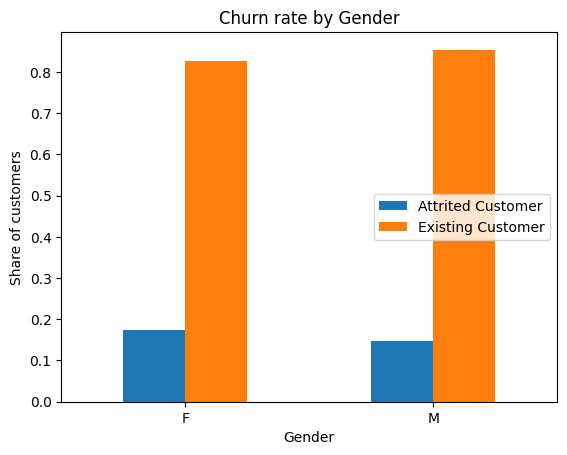

In [15]:
pd.crosstab(df["Gender"],df["Attrition_Flag"],normalize="index").plot(kind="bar")
plt.title("Churn rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Share of customers")
plt.xticks(rotation=0)
plt.legend(loc="center right")
plt.show()

### Chart 3: Insights
- About 17% of female customers left, compared with about 15% of male customers. Most customers of both
  genders stayed.
- The churn rate is only slightly higher for
  females. The difference is small, so gender alone does not
  separate customers who leave from customers who stay.
- Gender is a weak feature on its own. Other columns,
  such as transaction count and months inactive, need to be checked.

### Chart 4 :Total Transaction Count and Churn
Do customers who left use their card fewer times than customers who stayed?

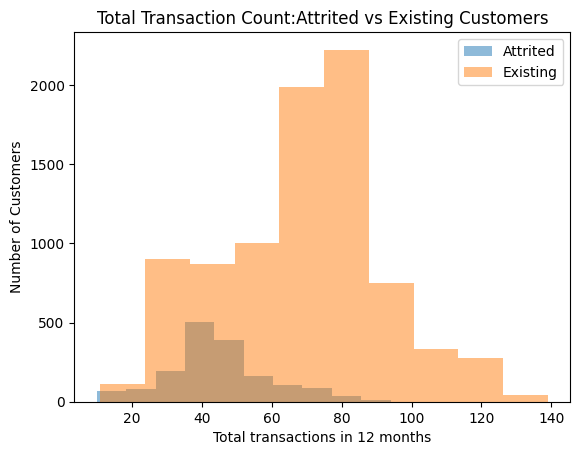

In [16]:
left=df[df["Attrition_Flag"]=="Attrited Customer"]
left.shape
stayed=df[df["Attrition_Flag"]=="Existing Customer"]
stayed.shape
plt.hist(left["Total_Trans_Ct"],label="Attrited",alpha=0.5)
plt.hist(stayed["Total_Trans_Ct"],label="Existing",alpha=0.5)
plt.legend()
plt.title("Total Transaction Count:Attrited vs Existing Customers")
plt.xlabel("Total transactions in 12 months")
plt.ylabel("Number of Customers")
plt.show()

In [17]:
left["Total_Trans_Ct"].mean()

np.float64(44.93362015980332)

In [18]:
stayed["Total_Trans_Ct"].mean()

np.float64(68.67258823529411)

### Chart 4: Insights
- Attrited customers are mostly between about
  35 and 55 transactions, with a peak near 40. Existing customers
  are spread much wider, with a peak near 80 and some above 100.
  The mean is 44.9 for attrited customers and 68.7 for existing
  customers.
- Customers who left used their card much less
  than customers who stayed, about 24 fewer transactions on
  average. Unlike age and gender, transaction count clearly
  separates the two groups.
- Total_Trans_Ct looks like a strong feature for the model.
  Months inactive and total transaction amount should also be checked.

### Chart 5 :Months_Inactive_12_mon vs Churn
Do customers who left have more inactive months than customers who stayed?

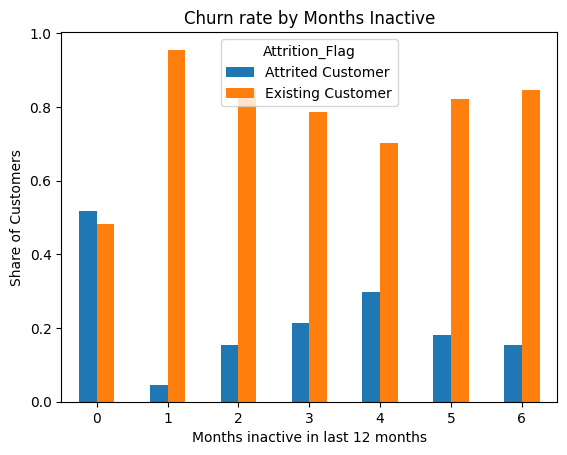

In [19]:
pd.crosstab(df["Months_Inactive_12_mon"],df["Attrition_Flag"],normalize="index").plot(kind="bar")
plt.title("Churn rate by Months Inactive")
plt.xlabel("Months inactive in last 12 months")
plt.ylabel("Share of Customers")
plt.xticks(rotation=0)
plt.show()

In [20]:
df["Months_Inactive_12_mon"].value_counts()

Months_Inactive_12_mon
3    3846
2    3282
1    2233
4     435
5     178
6     124
0      29
Name: count, dtype: int64

### Chart 5: Insights
- The share of customers who left rises from
  about 5% at 1 inactive month to about 30% at 4 inactive months.
  It then falls again at 5 and 6 months (about 15 to 18%). The
  group with 0 inactive months shows the highest share (about 52%),
  but it has only 29 customers.
- More inactive months is linked with more
  churn up to 4 months, but the relationship is not a straight
  line. The groups with 0, 5 and 6 months are small (29, 178 and
  124 customers), so their rates are not reliable.
- Months_Inactive_12_mon is a useful feature, but it is
  weaker than Total_Trans_Ct.

## Average of each column :Attrited vs Existing Customers

In [21]:
df.groupby("Attrition_Flag").mean(numeric_only=True)

,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
Attrition_Flag,,,,,,,,,,,,,,,,,
Attrited Customer,7.352614e+08,46.659496,2.402581,36.178242,3.279656,2.693301,2.972342,8136.039459,672.822987,7463.216472,0.694277,3095.025814,44.933620,0.554386,0.162475,0.994909,0.005091
Existing Customer,7.399272e+08,46.262118,2.335412,35.880588,3.914588,2.273765,2.356353,8726.877518,1256.604118,7470.273400,0.772510,4654.655882,68.672588,0.742434,0.296412,0.000186,0.999814


### Insights: Average of each column

- The biggest differences between attrited and
  existing customers are in Total_Revolving_Bal (673 vs 1257),
  Avg_Utilization_Ratio (0.16 vs 0.30), Total_Trans_Amt (3095 vs
  4655), Total_Trans_Ct (44.9 vs 68.7) and Total_Ct_Chng_Q4_Q1
  (0.55 vs 0.74). Attrited customers also contacted the bank more
  often (2.97 vs 2.36 times) and used fewer bank products
  (3.28 vs 3.91). Customer_Age, Months_on_book, Dependent_count and
  Avg_Open_To_Buy are almost the same for both groups.
- Customers who left used their card much less:
  they spent less, made fewer transactions, carried a lower
  balance and their usage dropped between Q1 and Q4. Age and
  length of relationship do not separate the two groups. Columns
  about card usage separate them the most.
- Averages can be misleading for columns with a few very
  large values (such as Credit_Limit and Total_Trans_Amt), so the
  model's feature importance will confirm which columns matter.

### Chart 6 : Correlation Heatmap
Which columns are related to each other,and which are related to churn?

In [22]:
columns=["Customer_Age","Dependent_count","Months_on_book","Total_Relationship_Count","Months_Inactive_12_mon","Contacts_Count_12_mon","Credit_Limit","Total_Revolving_Bal","Avg_Open_To_Buy","Total_Amt_Chng_Q4_Q1","Total_Trans_Amt","Total_Trans_Ct","Total_Ct_Chng_Q4_Q1","Avg_Utilization_Ratio"]
corr_table=df[columns].corr()

In [23]:
import seaborn as sns

Text(0.5, 1.0, 'Correlation Heatmap')

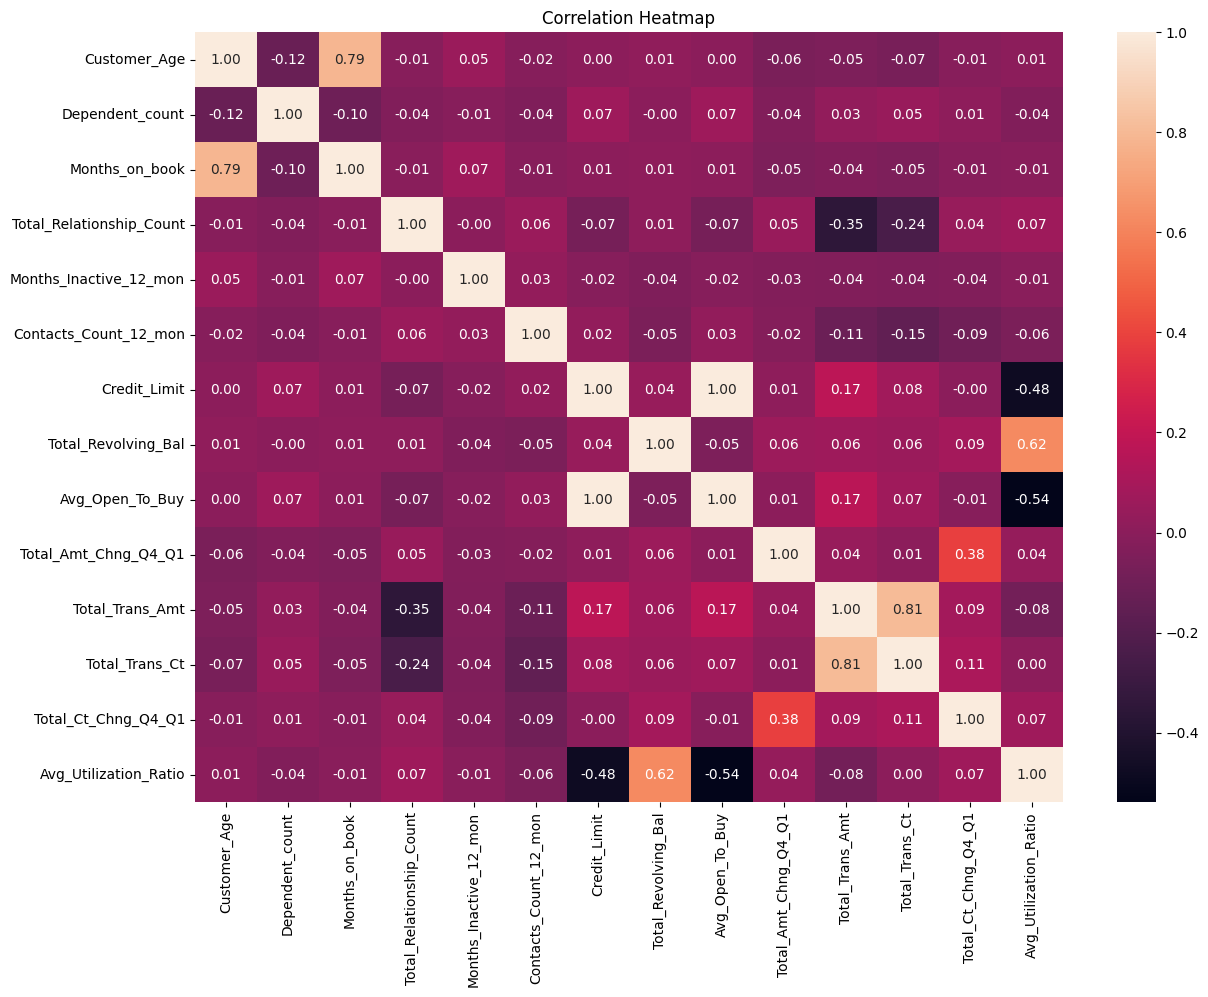

In [24]:
plt.figure(figsize=(14,10))
sns.heatmap(corr_table,annot=True,fmt=".2f")
plt.title("Correlation Heatmap")


### Chart 6: Insights
- Credit_Limit and Avg_Open_To_Buy are almost
  perfectly related (about 1). Total_Trans_Amt and Total_Trans_Ct
  are strongly related (about 0.81), and Customer_Age and
  Months_on_book are strongly related (about 0.79). Most other
  pairs have a weak relationship (close to 0).
- Strongly related columns carry almost the
  same information. Avg_Open_To_Buy can be calculated from
  Credit_Limit and Total_Revolving_Bal, so it repeats information.
  This is called multicollinearity.
- In preprocessing, consider dropping Avg_Open_To_Buy
  (it repeats Credit_Limit). Tree-based models handle related
  columns better than Logistic Regression.

### BOXPLOT : Detecting outliers

In [25]:
numerical_columns = df.select_dtypes(include='number').columns.drop([
    'CLIENTNUM',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
])

In [26]:
numerical_columns

Index(['Customer_Age', 'Dependent_count', 'Months_on_book',
       'Total_Relationship_Count', 'Months_Inactive_12_mon',
       'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal',
       'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt',
       'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio'],
      dtype='object')

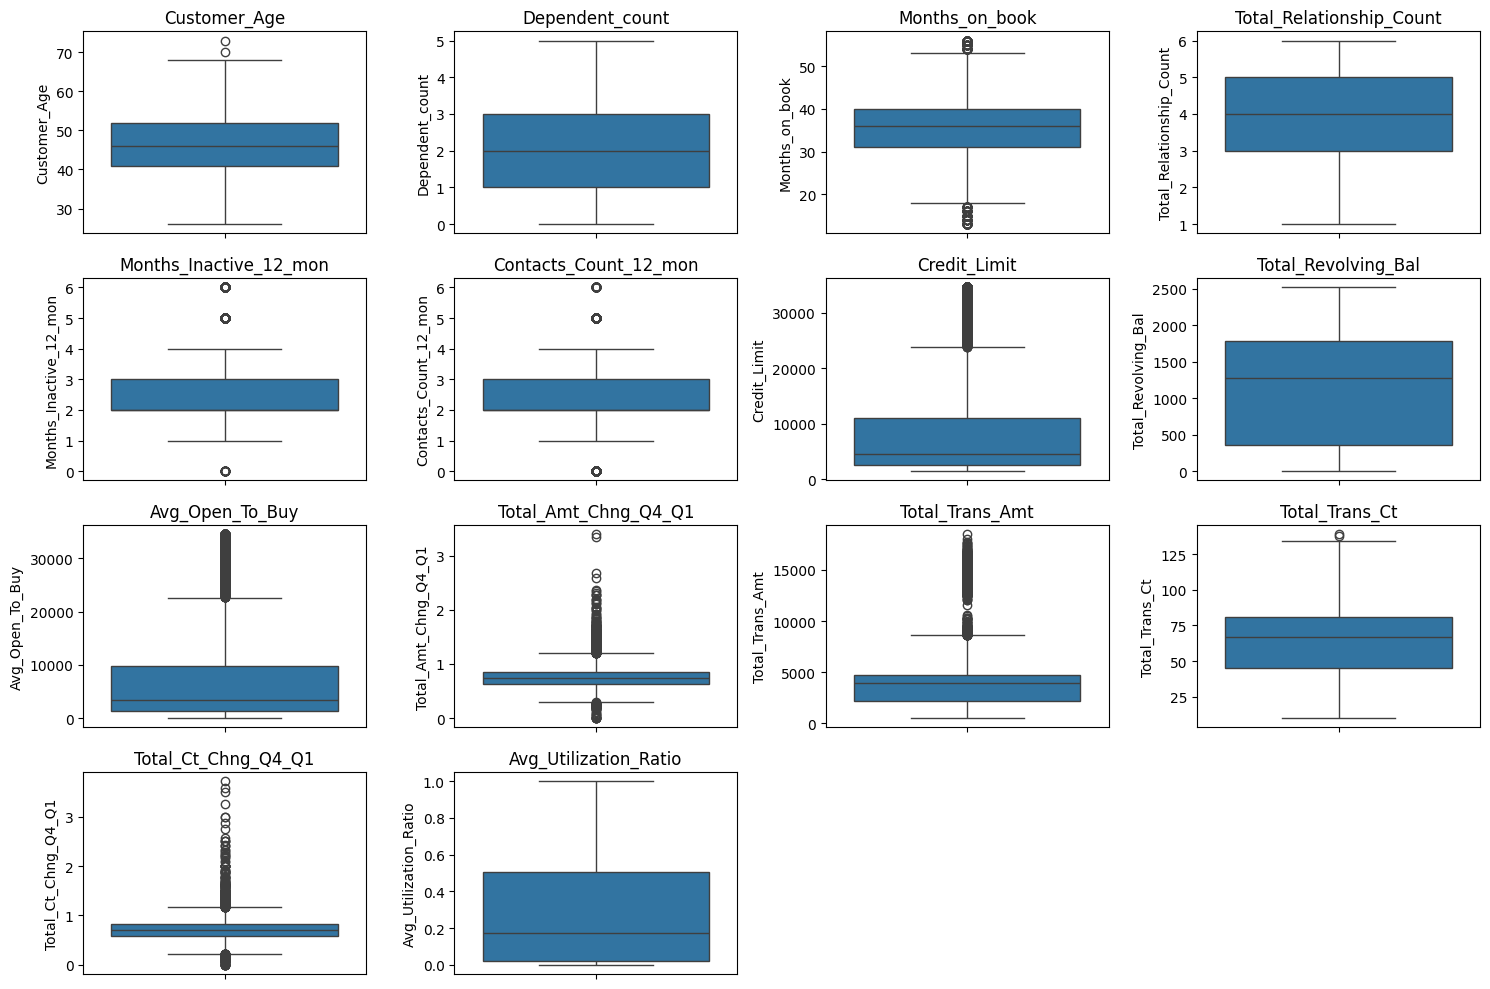

In [27]:
plt.figure(figsize=(15,10))
for i ,column in enumerate(numerical_columns):
    plt.subplot(4,4,i+1)
    sns.boxplot(y=df[column])
    plt.title(column)
plt.tight_layout()
plt.show()

In [28]:
outlier_counts = {}

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_counts[column] = len(outliers)

outlier_df = pd.DataFrame(
    list(outlier_counts.items()),
    columns=['Column', 'Outlier_Count']
)

outlier_df


,Column,Outlier_Count
0,Customer_Age,2
1,Dependent_count,0
2,Months_on_book,386
3,Total_Relationship_Count,0
4,Months_Inactive_12_mon,331
5,Contacts_Count_12_mon,629
6,Credit_Limit,984
7,Total_Revolving_Bal,0
8,Avg_Open_To_Buy,963
9,Total_Amt_Chng_Q4_Q1,396
